In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [2]:
master_df = pd.read_csv('data/master_data.csv')

C:\Users\Seyoung\AppData\Local\Temp\ipykernel_10780\4212149373.py:1: DtypeWarning: Columns (0,3,4,6,7,8,9,10,11,12,13,14,15,17,18,19,20,21,22,23,24,25,28,29,30,31,32,34,35,36,38,39,40,41,43,44,45,47,48,49,51,52,53,55,57,58,59,61,62,63) have mixed types. Specify dtype option on import or set low_memory=False.
  master_df = pd.read_csv('data/master_data.csv')


In [3]:

person_df = master_df.groupby('customer_id')

column_labels =['transaction_id','customer_id','abm_amount','abm_debit_credit','abm_datetime', 
                'abm_cash_indicator','abm_country', 'abm_province', 'abm_city',
                ]

master_df.columns

Index(['transaction_id', 'customer_id', 'abm_amount', 'abm_debit_credit',
       'abm_datetime', 'abm_cash_indicator', 'abm_country', 'abm_province',
       'abm_city', 'from_abm', 'customer_country', 'customer_province',
       'customer_city', 'customer_gender', 'customer_marital_status',
       'customer_occupation_code', 'customer_income', 'customer_birth_date',
       'customer_onboard_date', 'from_kyc_individual',
       'customer_occupation_title', 'from_kyc_occupation_codes',
       'business_country', 'business_province', 'business_city',
       'business_industry_code', 'business_employee_count', 'business_sales',
       'business_established_date', 'business_onboard_date',
       'from_kyc_smallbusiness', 'business_industry',
       'from_kyc_industry_codes', 'card_amount', 'card_debit_credit',
       'card_datetime', 'card_merchant_category', 'card_ecommerce_indicator',
       'card_country', 'card_province', 'card_city', 'from_card',
       'cheque_amount', 'cheque_debit_c

In [4]:
abm_df = master_df[['customer_id', 'abm_amount', 'abm_debit_credit', 'abm_datetime']].copy()
abm_df = abm_df.rename(columns={
    'abm_amount': 'amount',
    'abm_debit_credit': 'debit_credit',
    'abm_datetime': 'date'
})
abm_df['transaction_method'] = 'abm'
abm_df = abm_df.dropna(subset=['amount'])
abm_df['date'] = (
    pd.to_datetime(abm_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


card_df = master_df[['customer_id', 'card_amount', 'card_debit_credit', 'card_datetime']].copy()
card_df = card_df.rename(columns={
    'card_amount': 'amount',
    'card_debit_credit': 'debit_credit',
    'card_datetime': 'date'
})
card_df['transaction_method'] = 'card'
card_df = card_df.dropna(subset=['amount'])
card_df['date'] = (
    pd.to_datetime(card_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


cheque_df = master_df[['customer_id', 'cheque_amount', 'cheque_debit_credit', 'cheque_datetime']].copy()
cheque_df = cheque_df.rename(columns={
    'cheque_amount': 'amount',
    'cheque_debit_credit': 'debit_credit',
    'cheque_datetime': 'date'
})
cheque_df['transaction_method'] = 'cheque'
cheque_df = cheque_df.dropna(subset=['amount'])
cheque_df['date'] = (
    pd.to_datetime(cheque_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)



eft_df = master_df[['customer_id', 'eft_amount', 'eft_debit_credit', 'eft_datetime']].copy()
eft_df = eft_df.rename(columns={
    'eft_amount': 'amount',
    'eft_debit_credit': 'debit_credit',
    'eft_datetime': 'date'
})
eft_df['transaction_method'] = 'eft'
eft_df = eft_df.dropna(subset=['amount'])
eft_df['date'] = (
    pd.to_datetime(eft_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)



emt_df = master_df[['customer_id', 'emt_amount', 'emt_debit_credit', 'emt_datetime']].copy()
emt_df = emt_df.rename(columns={
    'emt_amount': 'amount',
    'emt_debit_credit': 'debit_credit',
    'emt_datetime': 'date'
})
emt_df['transaction_method'] = 'emt'
emt_df = emt_df.dropna(subset=['amount'])
emt_df['date'] = (
    pd.to_datetime(emt_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)



westernunion_df = master_df[['customer_id', 'westernunion_amount', 'westernunion_debit_credit', 'westernunion_datetime']].copy()
westernunion_df = westernunion_df.rename(columns={
    'westernunion_amount': 'amount',
    'westernunion_debit_credit': 'debit_credit',
    'westernunion_datetime': 'date'
})
westernunion_df['transaction_method'] = 'westernunion'
westernunion_df = westernunion_df.dropna(subset=['amount'])
westernunion_df['date'] = (
    pd.to_datetime(westernunion_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


wire_df = master_df[['customer_id', 'wire_amount', 'wire_debit_credit', 'wire_datetime']].copy()
wire_df = wire_df.rename(columns={
    'wire_amount': 'amount',
    'wire_debit_credit': 'debit_credit',
    'wire_datetime': 'date'
})
wire_df['transaction_method'] = 'wire'
wire_df = wire_df.dropna(subset=['amount'])
wire_df['date'] = (
    pd.to_datetime(wire_df['date'], utc=True, errors="coerce")
      .dt.tz_convert("America/Toronto")
      .dt.tz_localize(None)
)


transactions_long = pd.concat([abm_df, card_df, cheque_df, eft_df, emt_df,
                               westernunion_df, wire_df], ignore_index=True)


person_df = transactions_long.groupby('customer_id').agg(
    num_transactions = ('amount', 'count'),
    total_amount = ('amount', 'sum'),
    avg_amount = ('amount', 'mean'),
    max_amount = ('amount', 'max'),
    std_amount = ('amount', 'std'),
    num_debit = ('debit_credit', lambda x: (x=='debit').sum()),
    num_credit = ('debit_credit', lambda x: (x=='credit').sum()),
    num_abm = ('transaction_method', lambda x: (x=='abm').sum()),
    num_card = ('transaction_method', lambda x: (x=='card').sum()),
    num_cheque = ('transaction_method', lambda x: (x=='cheque').sum()),
    num_eft = ('transaction_method', lambda x: (x=='eft').sum()),
    num_emt = ('transaction_method', lambda x: (x=='emt').sum()),
    num_westernunion = ('transaction_method', lambda x: (x=='westernunion').sum()),
    num_wire = ('transaction_method', lambda x: (x=='wire').sum())
)

person_df

,num_transactions,total_amount,avg_amount,max_amount,std_amount,num_debit,num_credit,num_abm,num_card,num_cheque,num_eft,num_emt,num_westernunion,num_wire
customer_id,,,,,,,,,,,,,,
SYNID0100000167,18,11562.53,642.362778,3236.46,816.759765,0,0,0,0,1,17,0,0,0
SYNID0100000431,108,22360.92,207.045556,1753.40,332.131472,0,0,14,45,0,20,28,1,0
SYNID0100000485,40,10991.32,274.783000,2264.88,431.253783,0,0,2,19,0,19,0,0,0
SYNID0100000539,150,10409.15,69.394333,1066.48,148.966923,0,0,0,139,0,4,7,0,0
SYNID0100000932,219,175514.88,801.437808,125397.63,8510.250698,0,0,2,189,2,25,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SYNID0200999416,8,475.34,59.417500,241.70,80.820878,0,0,0,8,0,0,0,0,0
SYNID0200999425,9,16480.55,1831.172222,7294.78,2422.614588,0,0,0,0,0,9,0,0,0
SYNID0200999482,20,611931.39,30596.569500,442933.20,97883.731679,0,0,7,1,12,0,0,0,0


In [5]:
# logistic regression features

activity_features = transactions_long.groupby('customer_id').agg(
    total_transactions=('amount', 'count')
)

money_features = transactions_long.groupby('customer_id').agg(
    total_amount=('amount', 'sum'),
    avg_amount=('amount', 'mean'),
    max_amount=('amount', 'max'),
    std_amount=('amount', 'std')
)

debit_credit_features = transactions_long.groupby('customer_id').agg(
    num_debit=('debit_credit', lambda x: (x=='debit').sum()),
    num_credit=('debit_credit', lambda x: (x=='credit').sum())
)

debit_credit_features

channel_features = transactions_long.groupby(['customer_id', 'transaction_method'])['amount'].count().unstack(fill_value=0)

channel_features

transaction_method,abm,card,cheque,eft,emt,westernunion,wire
customer_id,,,,,,,
SYNID0100000167,0,0,1,17,0,0,0
SYNID0100000431,14,45,0,20,28,1,0
SYNID0100000485,2,19,0,19,0,0,0
SYNID0100000539,0,139,0,4,7,0,0
SYNID0100000932,2,189,2,25,1,0,0
...,...,...,...,...,...,...,...
SYNID0200999416,0,8,0,0,0,0,0
SYNID0200999425,0,0,0,9,0,0,0
SYNID0200999482,7,1,12,0,0,0,0


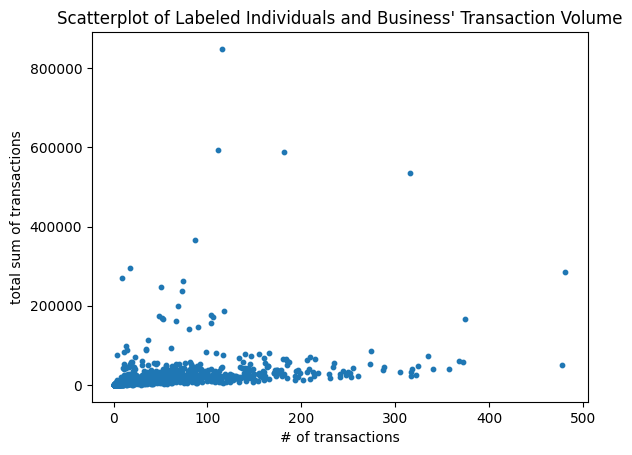

In [6]:
#quick data visualization on the labeled data
import matplotlib.pyplot as plt

labeled_df = pd.read_csv('data/labels.csv')

labeled_df['customer_id']

labeled_people_df = person_df[person_df.index.isin(labeled_df['customer_id'])]

labeled_people_df = labeled_people_df.merge(
    labeled_df[['customer_id','label']],
    on='customer_id',
    how='left'
)

labeled_people_df

plt.scatter(labeled_people_df['num_transactions'], 
            labeled_people_df['total_amount'],
            s=10 
            )
            
plt.ticklabel_format(style = 'plain', axis= 'y')
plt.xlabel('# of transactions')    
plt.ylabel('total sum of transactions') 
plt.title('Scatterplot of Labeled Individuals and Business\' Transaction Volume')
plt.show()

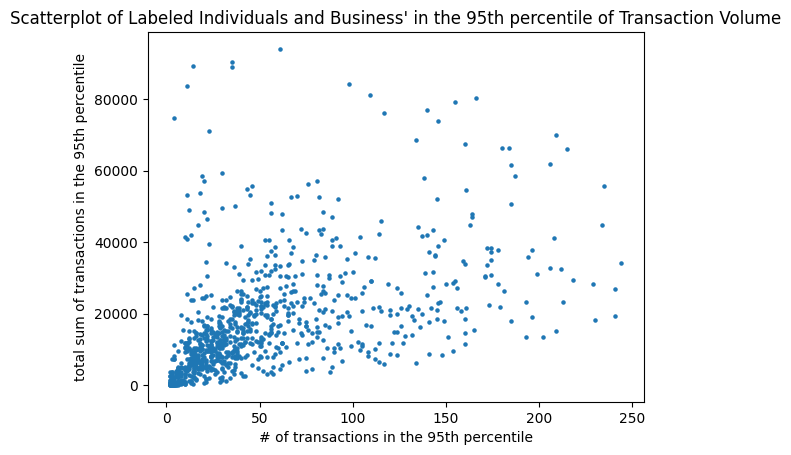

In [7]:
lower_x = labeled_people_df['num_transactions'].quantile(0.025)
upper_x = labeled_people_df['num_transactions'].quantile(0.975)

lower_y = labeled_people_df['total_amount'].quantile(0.025)
upper_y = labeled_people_df['total_amount'].quantile(0.975)

sum_filter = labeled_people_df[
    (labeled_people_df['num_transactions'] >= lower_x) & (labeled_people_df['num_transactions'] <= upper_x) &
    (labeled_people_df['total_amount'] >= lower_y) & (labeled_people_df['total_amount'] <= upper_y)
    ]

plt.scatter(sum_filter['num_transactions'], sum_filter['total_amount'], s = 5)
plt.xlabel('# of transactions in the 95th percentile')    
plt.ylabel('total sum of transactions in the 95th percentile') 
plt.title('Scatterplot of Labeled Individuals and Business\' in the 95th percentile of Transaction Volume')
plt.show()

C:\Users\Seyoung\AppData\Local\Temp\ipykernel_10780\919267959.py:12: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  total_invoice_amt = df.pivot_table(


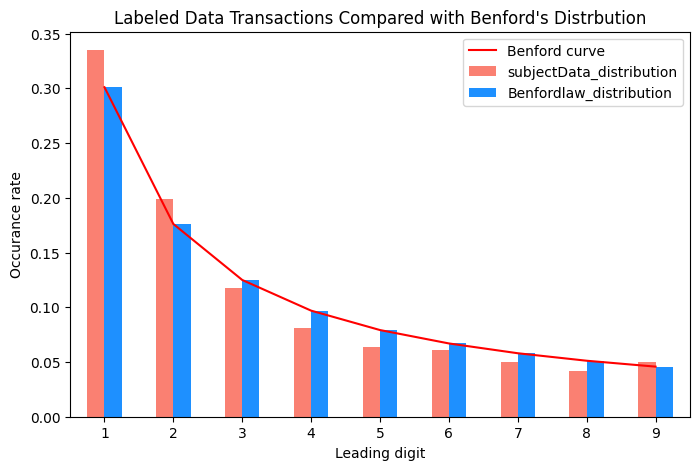

  extract_digit  amount_cad  amount_cad_frequency  subjectData_distribution  \
0             1  6164302.56                   335                     0.335   
1             2  5375879.95                   199                     0.199   
2             3  3114241.83                   118                     0.118   
3             4  1913938.36                    81                     0.081   
4             5  3229667.74                    64                     0.064   
5             6   824406.24                    61                     0.061   
6             7   814066.87                    50                     0.050   
7             8  1703317.17                    42                     0.042   
8             9   641857.45                    50                     0.050   

   Benfordlaw_distribution  
0                 0.301030  
1                 0.176091  
2                 0.124939  
3                 0.096910  
4                 0.079181  
5                 0.066947  
6     

In [8]:
df = pd.DataFrame() 

df['amount_cad'] = labeled_people_df['total_amount'].copy() 
df['extract_digit'] = df['amount_cad'].astype(str).str[:1] 


first_digit_count = df.pivot_table(
    values = ['amount_cad'],
    index = 'extract_digit', aggfunc= len, fill_value=''  
) 

total_invoice_amt = df.pivot_table(
    values = ['amount_cad'],
    index = 'extract_digit', aggfunc=sum, fill_value=''
)

df2 = total_invoice_amt.merge(first_digit_count, how = 'left',
                              left_on = 'extract_digit',
                              right_index= True,
                              suffixes = ['','_frequency'])

df2['subjectData_distribution'] = df2['amount_cad_frequency']/df2['amount_cad_frequency'].sum()

digits = np.arange(1,10)
benford_df = pd.DataFrame({
    'extract_digit': digits,
    'Benfordlaw_distribution': np.log10(1 + 1/digits)
})

benford_df['extract_digit'] = benford_df['extract_digit'].astype(str)


df2 = df2.merge(benford_df, on='extract_digit', how='left')


fig, ax = plt.subplots(figsize = (8, 5))
df2.reset_index()['Benfordlaw_distribution'].plot(kind = "line", ax = ax, secondary_y = False, color =  'red')
ax.legend(["Benford curve"])
df2.plot(kind = 'bar', x = 'extract_digit', y = ['subjectData_distribution','Benfordlaw_distribution'], 
        ax = ax, color = ['salmon','dodgerblue'], rot = 0)

plt.title('Labeled Data Transactions Compared with Benford\'s Distrbution')
plt.xlabel('Leading digit')
plt.ylabel('Occurance rate')
plt.show()


# print(first_digit_count)
# print(total_invoice_amt)
print(df2)


In [9]:
labeled_people_df.loc[labeled_people_df['label'] == 1]

labeled_people_df = labeled_people_df.set_index('customer_id')

In [10]:
labeled_people_df['std_amount'] = labeled_people_df['std_amount'].fillna(0)

X = labeled_people_df.drop(columns = 'label')

Y = labeled_people_df['label']

X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.3, random_state=21)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled)

log_reg = LogisticRegression(random_state = 0).fit(X_train_scaled, y_train)

[[-0.61160864 -0.40592279 -0.17868352 ...  0.67683176 -0.0600223
  -0.12828453]
 [ 0.08051894 -0.0387746  -0.16251212 ...  0.54144607  2.94109261
  -0.12828453]
 [-0.7169324  -0.30038593  0.2505242  ... -0.60933232 -0.0600223
  -0.12828453]
 ...
 [-0.35582236 -0.47158251 -0.35190492 ...  0.20298183 -0.0600223
  -0.12828453]
 [-0.44609987 -0.03265355  0.14277267 ... -0.60933232 -0.0600223
  -0.12828453]
 [ 0.21593521  5.62024368  2.3224029  ... -0.40625378 -0.0600223
  -0.12828453]]


In [11]:
log_reg.predict(X_train_scaled)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [12]:
log_reg.score(X_test_scaled, y_test)

0.9866666666666667

In [13]:
log_reg.score(X_train_scaled,y_train)

0.99

In [14]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

def evaluate_prob_model(name, model, X_te, y_te, threshold=0.5):
    """
    Evaluate a model using ROC-AUC + PR-AUC (PR-AUC is important for imbalanced AML labels).
    Works for models that implement predict_proba (logistic, RF, XGB).
    """
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)

    print(f"\n===== {name} (threshold={threshold}) =====")
    print("ROC-AUC :", roc_auc_score(y_te, proba))
    print("PR-AUC  :", average_precision_score(y_te, proba))
    print("Confusion matrix:\n", confusion_matrix(y_te, pred))
    print(classification_report(y_te, pred, digits=3))
    return proba

# Evaluate logistic regression properly (NOT just accuracy)
log_proba = evaluate_prob_model(
    "Logistic Regression",
    log_reg,
    X_test_scaled,   # scaled for logistic
    y_test,
    threshold=0.5
)


===== Logistic Regression (threshold=0.5) =====
ROC-AUC : 0.3406040268456376
PR-AUC  : 0.008541666666666666
Confusion matrix:
 [[296   2]
 [  2   0]]
              precision    recall  f1-score   support

           0      0.993     0.993     0.993       298
           1      0.000     0.000     0.000         2

    accuracy                          0.987       300
   macro avg      0.497     0.497     0.497       300
weighted avg      0.987     0.987     0.987       300



In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=21
)

rf.fit(X_train, y_train)

rf_proba = evaluate_prob_model(
    "Random Forest",
    rf,
    X_test,          # UNscaled for trees
    y_test,
    threshold=0.5
)


===== Random Forest (threshold=0.5) =====
ROC-AUC : 0.4597315436241611
PR-AUC  : 0.015631548068058
Confusion matrix:
 [[295   3]
 [  2   0]]
              precision    recall  f1-score   support

           0      0.993     0.990     0.992       298
           1      0.000     0.000     0.000         2

    accuracy                          0.983       300
   macro avg      0.497     0.495     0.496       300
weighted avg      0.987     0.983     0.985       300



In [16]:
from xgboost import XGBClassifier

pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

xgb = XGBClassifier(
    n_estimators=600,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1,
    random_state=21
)

xgb.fit(X_train, y_train)

xgb_proba = evaluate_prob_model(
    "XGBoost (Gradient Boosted Trees)",
    xgb,
    X_test,          # UNscaled for trees is fine
    y_test,
    threshold=0.5
)


===== XGBoost (Gradient Boosted Trees) (threshold=0.5) =====
ROC-AUC : 0.8129194630872483
PR-AUC  : 0.025807525807525808
Confusion matrix:
 [[295   3]
 [  2   0]]
              precision    recall  f1-score   support

           0      0.993     0.990     0.992       298
           1      0.000     0.000     0.000         2

    accuracy                          0.983       300
   macro avg      0.497     0.495     0.496       300
weighted avg      0.987     0.983     0.985       300



In [17]:
# Score the full population (all customers) with all three models (Logistic Regression, Random Forest, Gradient Boosted Tree)

X_new = person_df.copy()
X_new['std_amount'] = X_new['std_amount'].fillna(0)

# 1) Logistic Regression (needs scaling)
X_new_scaled = scaler.transform(X_new)

log_probabilities = log_reg.predict_proba(X_new_scaled)[:, 1]
log_threshold = 0.1
log_flags = (log_probabilities >= log_threshold).astype(int)

# 2) Random Forest (NO scaling)
rf_probabilities = rf.predict_proba(X_new)[:, 1]
rf_threshold = 0.1
rf_flags = (rf_probabilities >= rf_threshold).astype(int)

# 3) XGBoost (NO scaling)
xgb_probabilities = xgb.predict_proba(X_new)[:, 1]
xgb_threshold = 0.1
xgb_flags = (xgb_probabilities >= xgb_threshold).astype(int)

# Attach results to the same dataframe
X_new['log_prob'] = log_probabilities
X_new['log_flag'] = log_flags

X_new['rf_prob'] = rf_probabilities
X_new['rf_flag'] = rf_flags

X_new['xgb_prob'] = xgb_probabilities
X_new['xgb_flag'] = xgb_flags

# Quick sanity check: how many customers each model flags
print("Flag counts @ threshold 0.1")
print("Logistic:", X_new['log_flag'].sum())
print("RF      :", X_new['rf_flag'].sum())
print("XGBoost  :", X_new['xgb_flag'].sum())

Flag counts @ threshold 0.1
Logistic: 3192
RF      : 18231
XGBoost  : 4578


In [18]:
top_n = 50  # change as you like

top_log = X_new.sort_values("log_prob", ascending=False).head(top_n)
top_rf  = X_new.sort_values("rf_prob", ascending=False).head(top_n)
top_xgb = X_new.sort_values("xgb_prob", ascending=False).head(top_n)

print("\nTop Logistic customers:")
display(top_log[["log_prob", "log_flag"]].head(10))

print("\nTop RF customers:")
display(top_rf[["rf_prob", "rf_flag"]].head(10))

print("\nTop XGBoost customers:")
display(top_xgb[["xgb_prob", "xgb_flag"]].head(10))


Top Logistic customers:


,log_prob,log_flag
customer_id,,
SYNID0200999280,1.0,1
SYNID0200996396,1.0,1
SYNID0101186911,1.0,1
SYNID0105579175,1.0,1
SYNID0200931678,1.0,1
SYNID0105359473,1.0,1
SYNID0200917657,1.0,1
SYNID0105351153,1.0,1
SYNID0200911238,1.0,1



Top RF customers:


,rf_prob,rf_flag
customer_id,,
SYNID0200755995,0.746550,1
SYNID0200763435,0.744811,1
SYNID0200498815,0.738035,1
SYNID0200061628,0.730328,1
SYNID0200534513,0.729352,1
SYNID0200109884,0.726311,1
SYNID0200353709,0.722915,1
SYNID0200075093,0.722270,1
SYNID0200789296,0.716157,1



Top XGBoost customers:


,xgb_prob,xgb_flag
customer_id,,
SYNID0105593361,0.998531,1
SYNID0200847807,0.998275,1
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,1
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,1


In [19]:
# Consensus flags: Flag only if multiple models agree

# Case 1: 2 out of 3 models agree
X_new["vote_sum"] = X_new["log_flag"] + X_new["rf_flag"] + X_new["xgb_flag"]
X_new["flag_2of3"] = (X_new["vote_sum"] >= 2).astype(int)

print("Consensus (2 of 3) flagged:", X_new["flag_2of3"].sum())

# Case 2: All 3 models agree (reduces false positives)
X_new["flag_3of3"] = (X_new["vote_sum"] == 3).astype(int)
print("Consensus (3 of 3) flagged:", X_new["flag_3of3"].sum())

Consensus (2 of 3) flagged: 5504
Consensus (3 of 3) flagged: 2241


In [20]:
# Model-by-model summary (after consensus flags)

def summarize_flags(df, flag_col, prob_col, top_n=10):
    print(f"\n--- {flag_col} summary ---")
    print("Flagged count:", int(df[flag_col].sum()))
    print("Flag rate:", round(df[flag_col].mean(), 4))

    top = df.sort_values(prob_col, ascending=False).head(top_n)
    display(top[[prob_col, flag_col]].head(top_n))

# Logistic summary
summarize_flags(X_new, "log_flag", "log_prob", top_n=10)

# Random Forest summary
summarize_flags(X_new, "rf_flag", "rf_prob", top_n=10)

# XGBoost summary
summarize_flags(X_new, "xgb_flag", "xgb_prob", top_n=10)

# Consensus summaries
summarize_flags(X_new, "flag_2of3", "xgb_prob", top_n=10)  # using xgb_prob just for sorting preview
summarize_flags(X_new, "flag_3of3", "xgb_prob", top_n=10)


--- log_flag summary ---
Flagged count: 3192
Flag rate: 0.052


,log_prob,log_flag
customer_id,,
SYNID0200999280,1.0,1
SYNID0200996396,1.0,1
SYNID0101186911,1.0,1
SYNID0105579175,1.0,1
SYNID0200931678,1.0,1
SYNID0105359473,1.0,1
SYNID0200917657,1.0,1
SYNID0105351153,1.0,1
SYNID0200911238,1.0,1



--- rf_flag summary ---
Flagged count: 18231
Flag rate: 0.2969


,rf_prob,rf_flag
customer_id,,
SYNID0200755995,0.746550,1
SYNID0200763435,0.744811,1
SYNID0200498815,0.738035,1
SYNID0200061628,0.730328,1
SYNID0200534513,0.729352,1
SYNID0200109884,0.726311,1
SYNID0200353709,0.722915,1
SYNID0200075093,0.722270,1
SYNID0200789296,0.716157,1



--- xgb_flag summary ---
Flagged count: 4578
Flag rate: 0.0745


,xgb_prob,xgb_flag
customer_id,,
SYNID0105593361,0.998531,1
SYNID0200847807,0.998275,1
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,1
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,1



--- flag_2of3 summary ---
Flagged count: 5504
Flag rate: 0.0896


,xgb_prob,flag_2of3
customer_id,,
SYNID0105593361,0.998531,1
SYNID0200847807,0.998275,1
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,1
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,1



--- flag_3of3 summary ---
Flagged count: 2241
Flag rate: 0.0365


,xgb_prob,flag_3of3
customer_id,,
SYNID0105593361,0.998531,0
SYNID0200847807,0.998275,0
SYNID0200567030,0.997653,1
SYNID0200755995,0.997566,1
SYNID0105660335,0.997534,1
SYNID0104511912,0.997371,1
SYNID0107334515,0.997012,0
SYNID0200458134,0.997009,1
SYNID0200755574,0.996998,0


In [21]:
# A prioritized list: Combined risk score + ranked case lists

# Average probability across models (simple + effective)
X_new["risk_score_mean"] = (X_new["log_prob"] + X_new["rf_prob"] + X_new["xgb_prob"]) / 3

# Case lists
case_list_2of3 = X_new[X_new["flag_2of3"] == 1].sort_values("risk_score_mean", ascending=False)
case_list_3of3 = X_new[X_new["flag_3of3"] == 1].sort_values("risk_score_mean", ascending=False)

print("Top 20 cases (2-of-3):")
display(case_list_2of3[["risk_score_mean","log_prob","rf_prob","xgb_prob","flag_2of3","flag_3of3"]].head(20))

print("Top 20 cases (3-of-3):")
display(case_list_3of3[["risk_score_mean","log_prob","rf_prob","xgb_prob","flag_2of3","flag_3of3"]].head(20))

Top 20 cases (2-of-3):


,risk_score_mean,log_prob,rf_prob,xgb_prob,flag_2of3,flag_3of3
customer_id,,,,,,
SYNID0200061628,0.906579,0.994719,0.730328,0.994691,1,1
SYNID0200075093,0.905318,0.999998,0.722270,0.993686,1,1
SYNID0200353709,0.904105,0.999999,0.722915,0.989401,1,1
SYNID0200498815,0.903607,0.999998,0.738035,0.972788,1,1
SYNID0200885292,0.899937,0.999452,0.710640,0.989718,1,1
SYNID0200293964,0.899254,0.998781,0.704332,0.994649,1,1
SYNID0200684273,0.896546,0.999299,0.708138,0.982202,1,1
SYNID0200623494,0.896421,0.991267,0.712606,0.985389,1,1
SYNID0200886350,0.895729,0.999899,0.705701,0.981587,1,1


Top 20 cases (3-of-3):


,risk_score_mean,log_prob,rf_prob,xgb_prob,flag_2of3,flag_3of3
customer_id,,,,,,
SYNID0200061628,0.906579,0.994719,0.730328,0.994691,1,1
SYNID0200075093,0.905318,0.999998,0.722270,0.993686,1,1
SYNID0200353709,0.904105,0.999999,0.722915,0.989401,1,1
SYNID0200498815,0.903607,0.999998,0.738035,0.972788,1,1
SYNID0200885292,0.899937,0.999452,0.710640,0.989718,1,1
SYNID0200293964,0.899254,0.998781,0.704332,0.994649,1,1
SYNID0200684273,0.896546,0.999299,0.708138,0.982202,1,1
SYNID0200623494,0.896421,0.991267,0.712606,0.985389,1,1
SYNID0200886350,0.895729,0.999899,0.705701,0.981587,1,1


In [22]:
# Reason codes: A system to answer why did the system flag this customer?

# Use high quantile cutoffs to tag “unusual” behavior
q99 = X_new.quantile(0.99, numeric_only=True)
q95 = X_new.quantile(0.95, numeric_only=True)

def reason_codes(row):
    reasons = []

    # transaction behavior
    if "num_transactions" in row and row["num_transactions"] >= q99.get("num_transactions", np.inf):
        reasons.append("Very high number of transactions")

    if "total_amount" in row and row["total_amount"] >= q99.get("total_amount", np.inf):
        reasons.append("Very high total transaction amount")

    if "std_amount" in row and row["std_amount"] >= q99.get("std_amount", np.inf):
        reasons.append("Highly irregular transaction amounts")

    # channel-specific
    for col, label in [
        ("wire_amount", "High wire transfer amount"),
        ("westernunion_amount", "High Western Union amount"),
        ("emt_amount", "High EMT amount"),
        ("eft_amount", "High EFT amount"),
        ("card_amount", "High card amount"),
        ("cheque_amount", "High cheque amount"),
        ("abm_amount", "High cash or ABM amount"),
    ]:
        if col in row and row[col] >= q99.get(col, np.inf):
            reasons.append(label)

    if "debit_credit_ratio" in row and row["debit_credit_ratio"] >= q99.get("debit_credit_ratio", np.inf):
        reasons.append("Unusual debit credit pattern")

    return "; ".join(reasons) if reasons else "No single extreme feature, interaction based risk"

# 1) Create the column
X_new["reason_codes"] = X_new.apply(reason_codes, axis=1)

# 2) Build case list (so it includes the new column)
case_list_2of3 = X_new[X_new["flag_2of3"] == 1].sort_values("risk_score_mean", ascending=False)

print("Example reasons for top 10 (2-of-3) cases:")
display(
    case_list_2of3
    .reset_index()
    [["customer_id", "risk_score_mean", "reason_codes"]]
    .head(10)
)

# Rebuild 3-of-3 case list after reason_codes column exists
case_list_3of3 = X_new[X_new["flag_3of3"] == 1] \
    .sort_values("risk_score_mean", ascending=False)

print("Example reasons for top 10 (3-of-3) cases:")
display(
    case_list_3of3
    .reset_index()
    [["customer_id", "risk_score_mean", "reason_codes"]]
    .head(10)
)

Example reasons for top 10 (2-of-3) cases:


,customer_id,risk_score_mean,reason_codes
0,SYNID0200061628,0.906579,"No single extreme feature, interaction based risk"
1,SYNID0200075093,0.905318,"No single extreme feature, interaction based risk"
2,SYNID0200353709,0.904105,Very high total transaction amount; Highly irr...
3,SYNID0200498815,0.903607,Highly irregular transaction amounts
4,SYNID0200885292,0.899937,"No single extreme feature, interaction based risk"
5,SYNID0200293964,0.899254,Very high total transaction amount
6,SYNID0200684273,0.896546,Very high total transaction amount
7,SYNID0200623494,0.896421,"No single extreme feature, interaction based risk"
8,SYNID0200886350,0.895729,"No single extreme feature, interaction based risk"
9,SYNID0200201331,0.895700,"No single extreme feature, interaction based risk"


Example reasons for top 10 (3-of-3) cases:


,customer_id,risk_score_mean,reason_codes
0,SYNID0200061628,0.906579,"No single extreme feature, interaction based risk"
1,SYNID0200075093,0.905318,"No single extreme feature, interaction based risk"
2,SYNID0200353709,0.904105,Very high total transaction amount; Highly irr...
3,SYNID0200498815,0.903607,Highly irregular transaction amounts
4,SYNID0200885292,0.899937,"No single extreme feature, interaction based risk"
5,SYNID0200293964,0.899254,Very high total transaction amount
6,SYNID0200684273,0.896546,Very high total transaction amount
7,SYNID0200623494,0.896421,"No single extreme feature, interaction based risk"
8,SYNID0200886350,0.895729,"No single extreme feature, interaction based risk"
9,SYNID0200201331,0.895700,"No single extreme feature, interaction based risk"


In [23]:
# Optional: Overlap analysis (how the 3 models agree)

log_set = set(X_new.index[X_new["log_flag"] == 1])
rf_set  = set(X_new.index[X_new["rf_flag"] == 1])
xgb_set = set(X_new.index[X_new["xgb_flag"] == 1])

print("Flag overlap counts:")
print("Log ∩ RF:", len(log_set & rf_set))
print("Log ∩ XGB:", len(log_set & xgb_set))
print("RF ∩ XGB:", len(rf_set & xgb_set))
print("All three:", len(log_set & rf_set & xgb_set))

Flag overlap counts:
Log ∩ RF: 3192
Log ∩ XGB: 2241
RF ∩ XGB: 4553
All three: 2241


In [24]:
# Evaluation with given (known) labels: We have 61k customers in total but
# only 1000 of them have labels and only 10 among the 1000 are suspicious as we can see from the code below.
# So, we can only evaluate on 1000 customers because those are the only ones with ground truth.

# Merge full population predictions with labeled customers only
full_eval = X_new.merge(
    labeled_df[['customer_id', 'label']],
    left_index=True,
    right_on='customer_id',
    how='inner'
)

print("Number of labeled customers used for evaluation:", len(full_eval))
print("Number of true suspicious in labeled set:", full_eval['label'].sum())

Number of labeled customers used for evaluation: 1000
Number of true suspicious in labeled set: 10


In [25]:
from sklearn.metrics import roc_auc_score, average_precision_score

def evaluate_ranking_model(df, score_col, label_col='label', top_percent=0.05):
    print(f"\n===== Evaluating: {score_col} =====")

    y_true = df[label_col]
    y_score = df[score_col]

    # AUC metrics
    roc = roc_auc_score(y_true, y_score)
    pr = average_precision_score(y_true, y_score)

    print("ROC-AUC:", round(roc, 4))
    print("PR-AUC :", round(pr, 4))

    # Top-k evaluation
    k = int(len(df) * top_percent)
    top_k = df.sort_values(score_col, ascending=False).head(k)

    recall_at_k = top_k[label_col].sum() / max(y_true.sum(), 1)
    precision_at_k = top_k[label_col].mean()

    print(f"Top {int(top_percent*100)}% cutoff (k={k})")
    print("Recall@Top%   :", round(recall_at_k, 4))
    print("Precision@Top%:", round(precision_at_k, 4))

    return {
        "roc_auc": roc,
        "pr_auc": pr,
        "recall_at_k": recall_at_k,
        "precision_at_k": precision_at_k
    }

In [26]:
results = {}

results['logistic'] = evaluate_ranking_model(full_eval, "log_prob")
results['rf']       = evaluate_ranking_model(full_eval, "rf_prob")
results['xgb']      = evaluate_ranking_model(full_eval, "xgb_prob")
results['mean']     = evaluate_ranking_model(full_eval, "risk_score_mean")


===== Evaluating: log_prob =====
ROC-AUC: 0.6963
PR-AUC : 0.0988
Top 5% cutoff (k=50)
Recall@Top%   : 0.2
Precision@Top%: 0.04

===== Evaluating: rf_prob =====
ROC-AUC: 0.8945
PR-AUC : 0.6392
Top 5% cutoff (k=50)
Recall@Top%   : 0.8
Precision@Top%: 0.16

===== Evaluating: xgb_prob =====
ROC-AUC: 0.9642
PR-AUC : 0.8111
Top 5% cutoff (k=50)
Recall@Top%   : 0.8
Precision@Top%: 0.16

===== Evaluating: risk_score_mean =====
ROC-AUC: 0.9045
PR-AUC : 0.4988
Top 5% cutoff (k=50)
Recall@Top%   : 0.8
Precision@Top%: 0.16


In [27]:
def evaluate_binary_flag(df, flag_col, label_col='label'):
    print(f"\n===== Evaluating flag rule: {flag_col} =====")

    flagged = df[df[flag_col] == 1]

    recall = flagged[label_col].sum() / max(df[label_col].sum(), 1)
    precision = flagged[label_col].mean() if len(flagged) > 0 else 0

    print("Total flagged:", len(flagged))
    print("Recall :", round(recall, 4))
    print("Precision:", round(precision, 4))

    return {
        "recall": recall,
        "precision": precision,
        "flagged": len(flagged)
    }

results['2of3'] = evaluate_binary_flag(full_eval, "flag_2of3")
results['3of3'] = evaluate_binary_flag(full_eval, "flag_3of3")


===== Evaluating flag rule: flag_2of3 =====
Total flagged: 25
Recall : 0.8
Precision: 0.32

===== Evaluating flag rule: flag_3of3 =====
Total flagged: 6
Recall : 0.2
Precision: 0.3333


In [34]:
def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    TP = int(((y_true == 1) & (y_pred == 1)).sum())
    TN = int(((y_true == 0) & (y_pred == 0)).sum())
    FP = int(((y_true == 0) & (y_pred == 1)).sum())
    FN = int(((y_true == 1) & (y_pred == 0)).sum())

    precision   = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall      = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0

    # Type I and Type II error rates
    type1_error = FP / (FP + TN) if (FP + TN) > 0 else 0.0  # FPR
    type2_error = FN / (FN + TP) if (FN + TP) > 0 else 0.0  # FNR

    return TP, FP, FN, TN, precision, recall, specificity, type1_error, type2_error


rows = []
thresholds = [round(x, 1) for x in np.arange(0.1, 1.0, 0.1)]
y_true = eval_df["label"].astype(int)

for t in thresholds:
    # 1) individual model predictions at this threshold
    log_pred = (eval_df["log_prob"] >= t).astype(int)
    rf_pred  = (eval_df["rf_prob"]  >= t).astype(int)
    xgb_pred = (eval_df["xgb_prob"] >= t).astype(int)

    # 2) consensus rules at this threshold
    vote_sum = log_pred + rf_pred + xgb_pred
    pred_2of3 = (vote_sum >= 2).astype(int)
    pred_3of3 = (vote_sum == 3).astype(int)

    pred_map = {
        "logistic": log_pred,
        "rf": rf_pred,
        "xgboost": xgb_pred,
        "consensus_2of3": pred_2of3,
        "consensus_3of3": pred_3of3
    }

    for model_name, y_pred in pred_map.items():
        TP, FP, FN, TN, precision, recall, specificity, type1, type2 = compute_metrics(y_true, y_pred)

        rows.append({
            "threshold": t,
            "model": model_name,
            "flags": int(y_pred.sum()),
            "TP": TP,
            "FP": FP,
            "FN": FN,
            "TN": TN,
            "precision": round(precision, 4),
            "recall": round(recall, 4),
            "specificity": round(specificity, 4),
            "type1_error_rate": round(type1, 4),
            "type2_error_rate": round(type2, 4)
        })

model_order = [
    "logistic",
    "rf",
    "xgboost",
    "consensus_2of3",
    "consensus_3of3"
]

results_df["model"] = pd.Categorical(
    results_df["model"],
    categories=model_order,
    ordered=True
)

results_df = results_df.sort_values(["threshold", "model"]).reset_index(drop=True)

display(results_df)

,threshold,model,flags,TP,FP,FN,TN,precision,recall,specificity,type1_error_rate,type2_error_rate
0,0.1,logistic,13,2,11,8,979,0.1538,0.2,0.9889,0.0111,0.8
1,0.1,rf,129,9,120,1,870,0.0698,0.9,0.8788,0.1212,0.1
2,0.1,xgboost,18,8,10,2,980,0.4444,0.8,0.9899,0.0101,0.2
3,0.1,consensus_2of3,25,8,17,2,973,0.3200,0.8,0.9828,0.0172,0.2
4,0.1,consensus_3of3,6,2,4,8,986,0.3333,0.2,0.9960,0.0040,0.8
5,0.2,logistic,7,2,5,8,985,0.2857,0.2,0.9949,0.0051,0.8
6,0.2,rf,51,8,43,2,947,0.1569,0.8,0.9566,0.0434,0.2
7,0.2,xgboost,16,8,8,2,982,0.5000,0.8,0.9919,0.0081,0.2
8,0.2,consensus_2of3,18,8,10,2,980,0.4444,0.8,0.9899,0.0101,0.2
9,0.2,consensus_3of3,5,2,3,8,987,0.4000,0.2,0.9970,0.0030,0.8


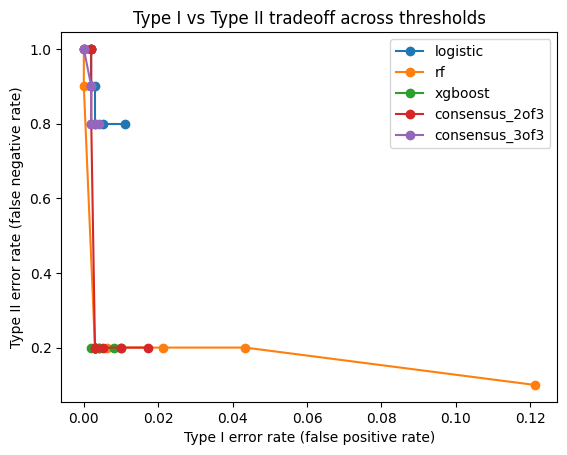

In [36]:
import matplotlib.pyplot as plt

plot_models = ["logistic", "rf", "xgboost", "consensus_2of3", "consensus_3of3"]

plt.figure()
for m in plot_models:
    dfm = results_df[results_df["model"] == m].sort_values("threshold")
    plt.plot(dfm["type1_error_rate"], dfm["type2_error_rate"], marker="o", label=m)

plt.xlabel("Type I error rate (false positive rate)")
plt.ylabel("Type II error rate (false negative rate)")
plt.title("Type I vs Type II tradeoff across thresholds")
plt.legend()
plt.show()

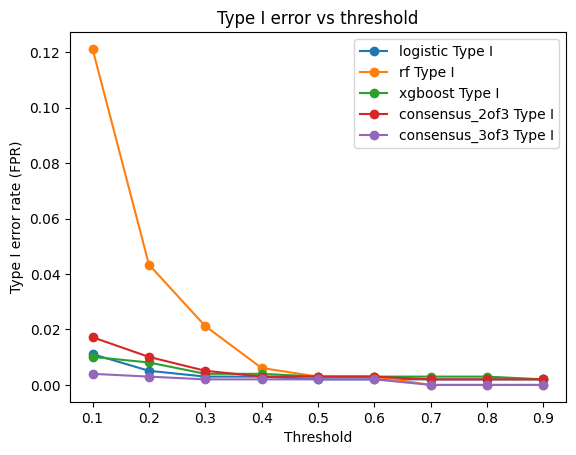

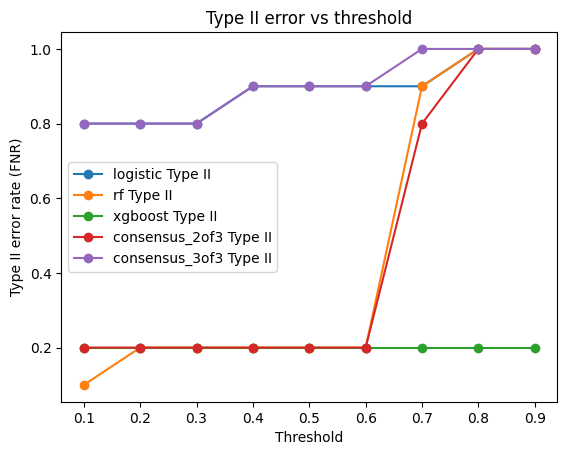

In [38]:
plt.figure()
for m in plot_models:
    dfm = results_df[results_df["model"] == m].sort_values("threshold")
    plt.plot(dfm["threshold"], dfm["type1_error_rate"], marker="o", label=f"{m} Type I")

plt.xlabel("Threshold")
plt.ylabel("Type I error rate (FPR)")
plt.title("Type I error vs threshold")
plt.legend()
plt.show()

plt.figure()
for m in plot_models:
    dfm = results_df[results_df["model"] == m].sort_values("threshold")
    plt.plot(dfm["threshold"], dfm["type2_error_rate"], marker="o", label=f"{m} Type II")

plt.xlabel("Threshold")
plt.ylabel("Type II error rate (FNR)")
plt.title("Type II error vs threshold")
plt.legend()
plt.show()

In [80]:
# Setup labeled matrix + train/test split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    make_scorer
)
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

# GLOBAL THRESHOLD
THRESHOLD = 0.6

# Labeled dataset setup
# Assumes labeled_people_df exists and has a label column.
labeled_people_df = labeled_people_df.dropna(subset=["label"]).copy()

# Features and labels
y = labeled_people_df["label"].astype(int)
X = labeled_people_df.drop(columns=["label"]).copy()

# Safety: replace missing numeric values
X = X.fillna(0)

# Stratified split keeps class balance similar in train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=21,
    stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train positives:", int((y_train==1).sum()), "Test positives:", int((y_test==1).sum()))

Train shape: (700, 14) Test shape: (300, 14)
Train positives: 7 Test positives: 3


In [ ]:
# logistic regression ENHANCEMENT (add interaction terms + penalty: Elastic Net (EN)) 

# Add interaction features
def add_interactions(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    needed = ["total_amount","num_wire","num_westernunion",
              "num_transactions","std_amount","num_debit","num_credit"]
    for c in needed:
        if c not in df.columns:
            df[c] = 0

    df["amt_x_wire"] = df["total_amount"] * df["num_wire"]
    df["amt_x_wu"]   = df["total_amount"] * df["num_westernunion"]
    df["txn_x_std"]  = df["num_transactions"] * df["std_amount"]

    df["debit_ratio"] = df["num_debit"] / (df["num_credit"] + 1)
    df["debit_ratio_x_amt"] = df["debit_ratio"] * df["total_amount"]
    return df

X_train_inter = add_interactions(X_train).fillna(0)
X_test_inter  = add_interactions(X_test).fillna(0)

# Enhanced logistic needs its own scaler (new feature space)
scaler_inter = StandardScaler()
X_train_sc_inter = scaler_inter.fit_transform(X_train_inter)
X_test_sc_inter  = scaler_inter.transform(X_test_inter)

# Enhanced Logistic Regression (elastic net)
log_reg_enh = LogisticRegression(
    penalty="elasticnet",
    solver="saga",
    l1_ratio=0.5,
    class_weight="balanced",
    max_iter=5000,
    random_state=21
)
log_reg_enh.fit(X_train_sc_inter, y_train)

C:\Users\Seyoung\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'elasticnet'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",21
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [82]:
# XGBoost ENHANCEMENT (learn from labeled data via tuning + optional calibration) 

# Imbalance weight (AML)
pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

# Base model for hyperparameter search (we are NOT touching your baseline xgb)
xgb_for_search = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1,
    random_state=21
)

param_dist = {
    "n_estimators": [300, 600, 1000, 1500],
    "learning_rate": [0.01, 0.02, 0.05, 0.1],
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 0.5, 1, 2],
    "reg_lambda": [1, 2, 5, 10],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)
pr_scorer = make_scorer(average_precision_score, needs_proba=True)

search = RandomizedSearchCV(
    xgb_for_search,
    param_distributions=param_dist,
    n_iter=25,
    scoring=pr_scorer,
    cv=cv,
    verbose=1,
    random_state=21
)

search.fit(X_train, y_train)
xgb_enh = search.best_estimator_

print("Enhanced XGB best CV PR-AUC:", search.best_score_)
print("Enhanced XGB best params:", search.best_params_)

# Calibrate enhanced XGB probabilities (optional but recommended)
xgb_enh_cal = CalibratedClassifierCV(xgb_enh, method="isotonic", cv=5)
xgb_enh_cal.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


C:\Users\Seyoung\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py:927: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "C:\Users\Seyoung\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py", line 916, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "C:\Users\Seyoung\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_scorer.py", line 317, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\S

Enhanced XGB best CV PR-AUC: nan
Enhanced XGB best params: {'subsample': 1.0, 'reg_lambda': 2, 'n_estimators': 1500, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.8}


,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","XGBClassifier...ree=None, ...)"
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary ` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[fl

In [84]:
# Reuse existing baseline models: log_reg, scaler, xgb, rf

# Baseline Logistic probs (needs scaling using your existing `scaler`)
X_test_sc_base = scaler.transform(X_test)
p_log_base = log_reg.predict_proba(X_test_sc_base)[:, 1]

# Baseline XGB probs (no scaling)
p_xgb_base = xgb.predict_proba(X_test)[:, 1]

# Baseline RF probs (no scaling)
p_rf_base = rf.predict_proba(X_test)[:, 1]

# Consensus flags based on threshold 0.6 per-model
log_flag = (p_log_base >= THRESHOLD).astype(int)
xgb_flag = (p_xgb_base >= THRESHOLD).astype(int)
rf_flag  = (p_rf_base  >= THRESHOLD).astype(int)

vote_sum = log_flag + rf_flag + xgb_flag
flag_2of3 = (vote_sum >= 2).astype(int)
flag_3of3 = (vote_sum == 3).astype(int)

print("Consensus flagged (2-of-3):", int(flag_2of3.sum()))
print("Consensus flagged (3-of-3):", int(flag_3of3.sum()))

Consensus flagged (2-of-3): 3
Consensus flagged (3-of-3): 0


In [85]:
# Compare baseline vs enhanced vs consensus (threshold=0.6)
def eval_from_proba(name, proba, y_true, threshold=THRESHOLD):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()

    roc = roc_auc_score(y_true, proba) if len(np.unique(y_true)) > 1 else np.nan
    pr  = average_precision_score(y_true, proba) if len(np.unique(y_true)) > 1 else np.nan

    precision = tp/(tp+fp) if (tp+fp)>0 else 0
    recall    = tp/(tp+fn) if (tp+fn)>0 else 0
    specificity = tn/(tn+fp) if (tn+fp)>0 else 0
    type1 = fp/(fp+tn) if (fp+tn)>0 else 0
    type2 = fn/(fn+tp) if (fn+tp)>0 else 0

    return {
        "model": name,
        "threshold": threshold,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "type_1_error(FPR)": type1,
        "type_2_error(FNR)": type2,
        "ROC_AUC": roc,
        "PR_AUC": pr
    }

def eval_from_pred(name, pred, y_true):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    precision = tp/(tp+fp) if (tp+fp)>0 else 0
    recall    = tp/(tp+fn) if (tp+fn)>0 else 0
    specificity = tn/(tn+fp) if (tn+fp)>0 else 0
    type1 = fp/(fp+tn) if (fp+tn)>0 else 0
    type2 = fn/(fn+tp) if (fn+tp)>0 else 0

    return {
        "model": name,
        "threshold": np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "type_1_error(FPR)": type1,
        "type_2_error(FNR)": type2,
        "ROC_AUC": np.nan,
        "PR_AUC": np.nan
    }

# Enhanced model probabilities
p_log_enh = log_reg_enh.predict_proba(X_test_sc_inter)[:, 1]
p_xgb_enh = xgb_enh_cal.predict_proba(X_test)[:, 1]

rows = []
rows.append(eval_from_proba("Logistic (baseline, reused)", p_log_base, y_test))
rows.append(eval_from_proba("Logistic (enhanced interactions)", p_log_enh, y_test))
rows.append(eval_from_proba("XGBoost (baseline, reused)", p_xgb_base, y_test))
rows.append(eval_from_proba("XGBoost (enhanced tuned+calibrated)", p_xgb_enh, y_test))
rows.append(eval_from_pred("Consensus 2-of-3 @0.6 (baseline models)", flag_2of3, y_test))
rows.append(eval_from_pred("Consensus 3-of-3 @0.6 (baseline models)", flag_3of3, y_test))

comparison_df = pd.DataFrame(rows)
display(comparison_df.sort_values(by=["PR_AUC", "recall", "precision"], ascending=False))

,model,threshold,TP,FP,FN,TN,precision,recall,specificity,type_1_error(FPR),type_2_error(FNR),ROC_AUC,PR_AUC
2,"XGBoost (baseline, reused)",0.6,3,0,0,297,1.0,1.0,1.00000,0.00000,0.0,1.000000,1.000000
0,"Logistic (baseline, reused)",0.6,0,0,3,297,0.0,0.0,1.00000,0.00000,1.0,0.947250,0.231746
3,XGBoost (enhanced tuned+calibrated),0.6,0,0,3,297,0.0,0.0,1.00000,0.00000,1.0,0.706510,0.045721
1,Logistic (enhanced interactions),0.6,0,20,3,277,0.0,0.0,0.93266,0.06734,1.0,0.514029,0.017853
4,Consensus 2-of-3 @0.6 (baseline models),NaN,3,0,0,297,1.0,1.0,1.00000,0.00000,0.0,NaN,NaN
5,Consensus 3-of-3 @0.6 (baseline models),NaN,0,0,3,297,0.0,0.0,1.00000,0.00000,1.0,NaN,NaN


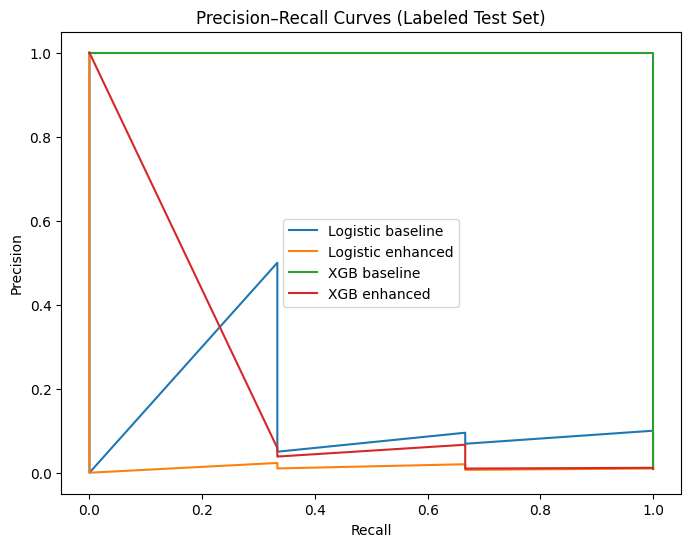

In [88]:
# PR curves: only for probabilistic models
plt.figure(figsize=(8, 6))
for name, proba in [
    ("Logistic baseline", p_log_base),
    ("Logistic enhanced", p_log_enh),
    ("XGB baseline", p_xgb_base),
    ("XGB enhanced", p_xgb_enh),
]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    plt.plot(rec, prec, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves (Labeled Test Set)")
plt.legend()
plt.show()